# Actividad | Dataset - Notebook | Individual

**Curso:** TC5061 - Operaciones de aprendizaje automático 

**Alumna:** Ariadna del carmen Tapia Miranda

**Matrícula:** A01840093   

In [4]:
# !pip install mlflow scikit-learn pandas numpy matplotlib seaborn - ambiente nuevo
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Modelado y evaluación
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# Tracking de experimentos
import mlflow
import mlflow.sklearn

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## 1)  Dataset
Se utiliza el **Wine Quality Dataset** (red wine) cargado en línea directamente desde el UCI Machine Learning Repository.
- **Instancias:** 1,599 registros.
- **Variables predictoras:** 11 atributos fisicoquímicos continuos (`fixed acidity`, `volatile acidity`, `citric acid`, `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`, `density`, `pH`, `sulphates`, `alcohol`).
- **Variable objetivo:** `quality` (puntuación entera entre 0 y 10). Para este baseline la binarizaremos en:
  - `1` (Alta calidad: puntaje >= 7)
  - `0` (Calidad estándar/baja: puntaje < 7)

In [6]:
# Carga directa en línea
url_wine = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url_wine, sep=';')

print("Dimensiones iniciales:", df.shape)
print("\nPrimeras 5 filas:")
display(df.head())

print("\nInformación:")
df.info()

Dimensiones iniciales: (1599, 12)

Primeras 5 filas:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Información:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


## 2) Análisis Exploratorio de Datos (EDA)
Analizamos estadísticas descriptivas, la distribución de la calidad del vino y la correlación entre variables para detectar multicolinealidad o relaciones directas con el objetivo.

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


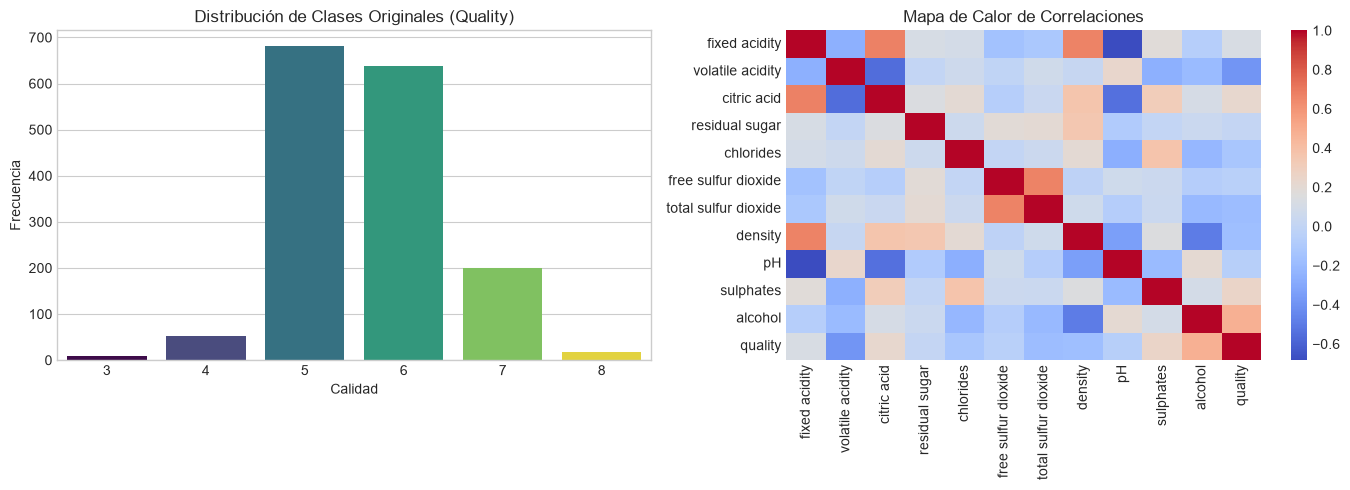

In [11]:
# Resumen estadístico
display(df.describe().T)

# Visualización de la distribución de la variable objetivo original
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='quality', palette='viridis', ax=axes[0], hue='quality', legend=False)
axes[0].set_title("Distribución de Clases Originales (Quality)", fontsize=12)
axes[0].set_xlabel("Calidad")
axes[0].set_ylabel("Frecuencia")

# Matriz de correlación
corr_matrix = df.corr()
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, ax=axes[1])
axes[1].set_title("Mapa de Calor de Correlaciones", fontsize=12)

plt.tight_layout()
plt.show()

## 3) Limpieza y preprocesamiento de datos
**Decisiones de calidad de datos:**
1. **Valores nulos:** Se verifica la integridad; no existen valores vacíos en la fuente original.
2. **Duplicados:** Se detectan registros duplicados idénticos generados por muestras químicas idénticas. Para evitar sesgo y fuga en la partición, se eliminan.
3. **Outliers:** Si bien existen colas pesadas en variables como `residual sugar` y `chlorides`, en esta etapa de baseline se conservan para no distorsionar distribuciones sin justificación de negocio previa.
4. **Transformación objetivo:** Se define una clasificación binaria donde `calidad >= 7` define vino de alta calidad (clase minoritaria relevante).

In [ ]:
# Comprobación de nulos, no hay
print("Valores faltantes por columna:\n", df.isnull().sum())

# Duplicados
n_duplicados = df.duplicated().sum()
print(f"\nRegistros duplicados detectados: {n_duplicados}")
df_cleaned = df.drop_duplicates().copy()
print(f"Registros tras eliminar duplicados: {df_cleaned.shape[0]}")

# 3. Definición de objetivo binario (1: Bueno >= 7, 0: Regular/Bajo < 7)
df_cleaned['target'] = (df_cleaned['quality'] >= 7).astype(int)

# Separación de features (X) y target (y)
X = df_cleaned.drop(columns=['quality', 'target'])
y = df_cleaned['target']

# División (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Tamaño conjunto entrenamiento: {X_train.shape}")
print(f"Tamaño conjunto prueba: {X_test.shape}")
print(f"Distribución del target en prueba:\n{y_test.value_counts(normalize=True)}")

Valores faltantes por columna:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Registros duplicados detectados: 240
Registros tras eliminar duplicados: 1359
Tamaño conjunto entrenamiento: (1087, 11)
Tamaño conjunto prueba: (272, 11)
Distribución del target en prueba:
target
0    0.863971
1    0.136029
Name: proportion, dtype: float64


## 4, 5 y 6) Entrenamiento, Evaluación y MLflow Tracking
- **Modelo:** `LogisticRegression` (Baseline lineal e interpretable).
- **Métricas:** 
  - `Accuracy`: Proporción general de aciertos.
  - `F1-Score (Macro y Weighted)`: Métrica clave debido al desbalance natural de clases (menos vinos con calidad >= 7).
- **MLflow Tracking:** Se inicializa un experimento local (`Wine_Quality_Baseline`), registrando hiperparámetros, métricas de test, artefactos de matriz de confusión y el modelo serializado.

In [13]:
# Configuración del experimento en MLflow
mlflow.set_experiment("Wine_Quality_Baseline_Diagnostic")

# Parámetros del modelo
params = {
    "solver": "liblinear",
    "C": 1.0,
    "max_iter": 500,
    "random_state": 42
}

with mlflow.start_run(run_name="Baseline_LogisticRegression"):
    # 1. Registro de parámetros y metadatos
    mlflow.log_params(params)
    mlflow.log_param("test_size", 0.20)
    mlflow.log_param("features_count", X.shape[1])
    mlflow.set_tag("model_type", "baseline_linear")

    # 2. Entrenamiento del modelo
    model = LogisticRegression(**params)
    model.fit(X_train, y_train)

    # 3. Inferencia y cálculo de métricas
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    f1_macro = f1_score(y_test, y_pred, average='macro')

    # Registro de métricas en MLflow
    mlflow.log_metric("accuracy", acc)
    mlflow.log_metric("f1_weighted", f1_weighted)
    mlflow.log_metric("f1_macro", f1_macro)

    # 4. Generación y registro del artefacto visual (Matriz de Confusión)
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Baja/Media', 'Alta'], yticklabels=['Baja/Media', 'Alta'])
    plt.title("Matriz de Confusión - Baseline")
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    
    artifact_path = "confusion_matrix.png"
    plt.savefig(artifact_path, bbox_inches='tight')
    plt.close()
    
    mlflow.log_artifact(artifact_path)
    if os.path.exists(artifact_path):
        os.remove(artifact_path)

    # 5. Registro del modelo
    mlflow.sklearn.log_model(model, artifact_path="model")

    # Impresión de resultados en consola
    print("=== RESULTADOS DEL MODELO BASE ===")
    print(f"Accuracy:    {acc:.4f}")
    print(f"F1 Weighted: {f1_weighted:.4f}")
    print(f"F1 Macro:    {f1_macro:.4f}\n")
    print("Reporte de Clasificación:")
    print(classification_report(y_test, y_pred, target_names=['Baja/Media', 'Alta']))

2026/10/04 12:06:14 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/04 12:06:14 INFO mlflow.store.db.utils: Updating database tables
2026/10/04 12:06:17 INFO mlflow.tracking.fluent: Experiment with name 'Wine_Quality_Baseline_Diagnostic' does not exist. Creating a new experiment.
2026/10/04 12:06:18 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/04 12:06:53 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


=== RESULTADOS DEL MODELO BASE ===
Accuracy:    0.8750
F1 Weighted: 0.8444
F1 Macro:    0.6116

Reporte de Clasificación:
              precision    recall  f1-score   support

  Baja/Media       0.89      0.98      0.93       235
        Alta       0.64      0.19      0.29        37

    accuracy                           0.88       272
   macro avg       0.76      0.59      0.61       272
weighted avg       0.85      0.88      0.84       272



## 7) Reflexión

### 1. Mejoras al flujo actual mediante prácticas de MLOps
El flujo desarrollado en este notebook representa un prototipo funcional pero manual. Para transicionar este ejercicio a un estándar de ingeniería robusto y productivo, implementaría tres pilares esenciales de MLOps:
- **Versionado de datos y código (DVC + Git):** Aunque el código y los artefactos finales quedan registrados en MLflow, el dataset no cuenta con un linaje formal (*data lineage*) y depende de una fuente externa. Incorporar herramientas como DVC garantizaría la inmutabilidad de los datos de entrada, permitiendo reproducir con exactitud el estado del dataset utilizado.
- **Pipelines modulares y reproducibles:** El preprocesamiento actual depende de la memoria secuencial del notebook. Es importante estructurar el código en componentes desacoplados que puedan ejecutarse en pipelines(ej.`ingesta`, `validación`, `preprocesamiento`, `entrenamiento`) orquestados en pipelines y administrando las dependencias para eliminar discrepancias de entorno (ej. `contenedores`).
- **Automatización de CI/CD/CT:** Implementaría pruebas unitarias automáticas sobre la calidad del dato y validaciones de rendimiento mínimo antes de autorizar el registro o despliegue del modelo en un Model Registry.
- **Monitoreo y observabilidad continua:** Un modelo en producción sufre degradación por *concept drift* y *data drift*. Resulta crítico incorporar servicios de telemetría que comparen las distribuciones de inferencia contra la línea base de entrenamiento para disparar reentrenamientos automáticos.

### 2. Reflejo e impacto de estos aprendizajes en el área profesional
En el entorno empresarial, los modelos de Machine Learning no entregan valor de negocio real si permanecen como notebooks aislados. Demostrar maestría en el registro estructurado de parámetros, métricas y artefactos es la base para mitigar la deuda técnica en proyectos productivos (*Machine Learning Technical Debt*). 

Adoptar estas prácticas permite auditar decisiones algorítmicas, sustentar la gobernanza de modelos ante auditorías técnicas y facilitar la colaboración multidisciplinaria entre ingenieros de software, científicos de datos y arquitectos de soluciones así como tener una mejor trazabilidad al hacer troubleshoot cuando hay fallas y/o comportamientos inesperados. La reproducibilidad sistemática transforma el desarrollo de modelos de un arte experimental a un proceso de ingeniería de software confiable, escalable y mantenible.